# Rates and inflation: dynamics, numeraires and options

Family 25. P forecasting, bank-account Q valuation and terminal-forward
simulation are labeled separately. Inflation dynamics below use deterministic
nominal and real curves; no stochastic rate/CPI correlation is inferred.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2500)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Curve-fitted and standalone short-rate models

Hull–White and G2 fit the supplied discount curve at time zero. Vasicek and CIR
use supplied parameters and need not reproduce that curve at every maturity.

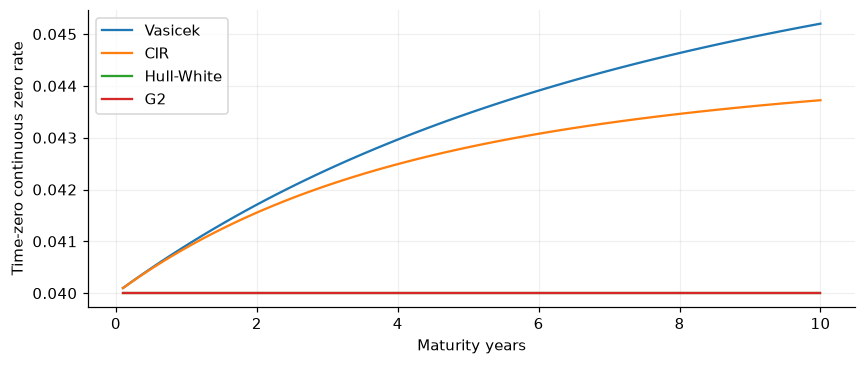

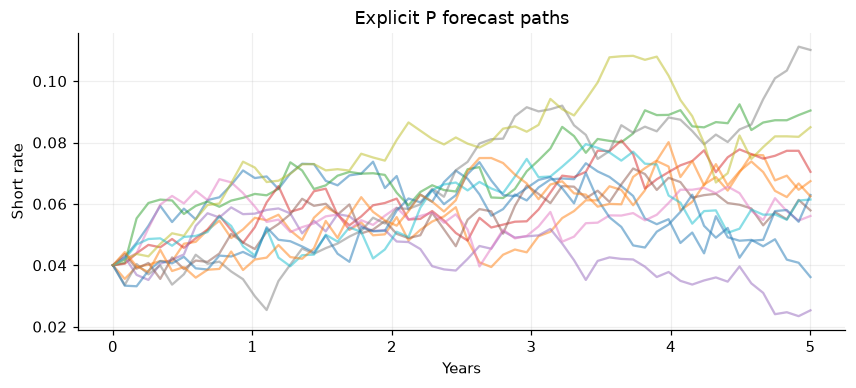

In [2]:
from convexity.math import rates as ra
models={
 'Vasicek':ra.ShortRateModel('vasicek',dict(r0=.04,kappa=.2,theta=.05,sigma=.01)),
 'CIR':ra.ShortRateModel('cir',dict(r0=.04,kappa=.2,theta=.05,sigma=.1)),
 'Hull-White':ra.ShortRateModel('hull_white',dict(kappa=.1,sigma=.01),discount),
 'G2':ra.ShortRateModel('g2',dict(a=.1,sigma=.01,b=.2,eta=.015,rho=-.5),discount)}
t=np.linspace(.1,10,70)
for name,m in models.items():
    state=[0.,0.] if name=='G2' else .04
    plt.plot(t,[-np.log(m.discount_bond(0,T,state))/T for T in t],label=name)
plt.xlabel('Maturity years');plt.ylabel('Time-zero continuous zero rate');plt.legend();plt.show()
physical=ra.ShortRateModel('vasicek',dict(r0=.04,kappa=.4,theta=.06,sigma=.015),measure='P')
paths=physical.process().sample(.04,np.linspace(0,5,60),draws=12,rng=rng)
plt.plot(paths.times,paths.values.T,alpha=.5);plt.xlabel('Years');plt.ylabel('Short rate');plt.title('Explicit P forecast paths');plt.show()

## Native HJM and a terminal-forward market model

QuantLib GSR provides a Gaussian HJM model. The market-model simulation uses a
terminal bond numeraire: the last forward rate has a martingale reference under
that measure, unlike an arbitrary bank-account-measure forward rate.

GSR initial 5-year discount: 0.8187307530779818


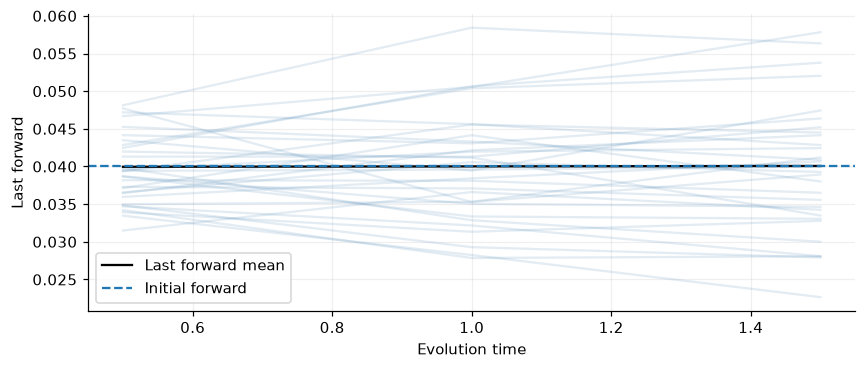

Simulation measure: terminal_forward


In [3]:
gsr=ra.gaussian_hjm(discount,['2027-01-01'],[.01,.015],[.1])
print('GSR initial 5-year discount:',ra.gaussian_bond_price(gsr,5.))
rate_times=[.5,1.,1.5,2.]
market_model=ra.forward_market_model(rate_times,[.04,.04,.04],volatility=.2,factors=2)
paths=ra.market_model_paths(market_model,draws=2500,seed=2517)
last=paths.values[:,:,-1]
plt.plot(paths.times,last[:30].T,alpha=.15,color='steelblue')
plt.plot(paths.times,last.mean(axis=0),color='black',label='Last forward mean');plt.axhline(.04,ls='--',label='Initial forward')
plt.xlabel('Evolution time');plt.ylabel('Last forward');plt.legend();plt.show()
print('Simulation measure:',paths.measure)

## Inflation levels and Q valuation

P expected CPI growth is an empirical assumption. With deterministic rates,
the Q forward CPI uses D_real / D_nominal. The CPI option is an option on the
index level; native inflation contracts additionally specify publication lags.

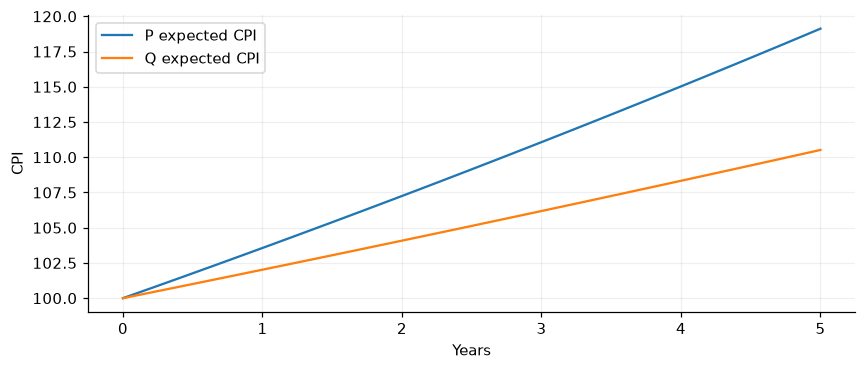

,CPI strike,Q two-year call
0,90,13.994913
1,100,7.404237
2,110,3.258063
3,120,1.198981


In [4]:
physical_cpi=ra.InflationDynamics(.1,'P',drift=.035)
pricing_cpi=ra.InflationDynamics(.1,'Q',nominal=discount,real=cv.flat_curve(ref,.02))
t=np.linspace(0,5,60)
plt.plot(t,[physical_cpi.transition(100,0,T).mean() for T in t],label='P expected CPI')
plt.plot(t,[pricing_cpi.transition(100,0,T).mean() for T in t],label='Q expected CPI');plt.xlabel('Years');plt.ylabel('CPI');plt.legend();plt.show()
display(pd.DataFrame([(s,pricing_cpi.option(100,s,2)) for s in [90,100,110,120]],columns=['CPI strike','Q two-year call']))

## Caps under different volatility specifications

A normal quote and a Black quote have different units. The model-based rate
option engine uses the same discount curve that fitted the Hull–White model.

In [5]:
dates=ct.schedule('2027-01-01','2030-01-01')
cap=ra.cap_floor(dates,ra.rate_index(discount),.04)
rows=[]
for method,vol in [('black',.2),('normal',.01),('analytic',None),('tree',None)]:
    result=ra.rate_option_price(cap,discount,method=method,volatility=vol,model=models['Hull-White'])
    rows.append((method,vol,result.value))
display(pd.DataFrame(rows,columns=['Engine','Volatility input','Cap value']))

,Engine,Volatility input,Cap value
0,black,0.20,1.244331
1,normal,0.01,1.569791
2,analytic,NaN,1.372729
3,tree,NaN,1.371814


## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.